In [108]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm, LogNorm


In [94]:
def safronov_number(m_star, a_planet, m_planet, r_planet):
    e2 = 0.001
    return 2 * (m_planet / m_star) * (a_planet / r_planet) / e2

In [90]:
def safronov_number(m_star, a_planet, m_planet,r_planet):
    G=4*np.pi*np.pi
    v_c_2=m_star/a_planet
    theta=2*m_planet/(r_planet*v_c_2*0.001)
    return theta

In [100]:
def safronov_number(m_star, a_planet, m_planet):
    # Units: solar masses, AU
    M_earth = 3.003e-6
    R_earth = 4.2635e-5

    m = np.asarray(m_planet) / M_earth

    # Chen & Kipping (2017)
    m1 = 2.04
    m2 = 0.414 * 9.545e-4 / M_earth

    r1 = 1.008 * m1**0.279
    r2 = r1 * (m2 / m1)**0.589

    r_planet = R_earth * np.where(
        m < m1,
        1.008 * m**0.279,
        np.where(
            m < m2,
            r1 * (m / m1)**0.589,
            r2 * (m / m2)**(-0.044)
        )
    )

    return (m_planet / m_star) * (a_planet / r_planet)

ValueError: vmin, vcenter, and vmax must be in ascending order

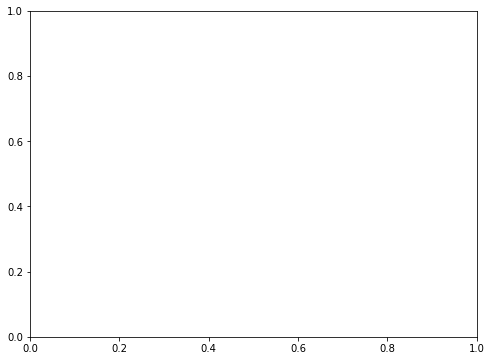

In [95]:



# Constants (AU, solar masses)
M_star = 1.0
R_jup = 0.0004779  # AU

# Parameter grid
a_planet = np.logspace(-1, 2, 200)      # AU
mass_ratio = np.logspace(-5, -2, 200)   # m_p / M_star

A, Q = np.meshgrid(a_planet, mass_ratio)
M_planet = Q * M_star

# Safronov number
theta = safronov_number(M_star, A, M_planet, R_jup/2)

# Heatmap
fig, ax = plt.subplots(figsize=(8, 6))

pcm = ax.pcolormesh(
    A, Q, np.log10(theta),
    norm=TwoSlopeNorm(
        vmin=np.log10(theta.min()),
        vcenter=0,
        vmax=np.log10(theta.max())
    ),
    cmap="RdBu_r",
    shading="auto"
)

cbar = fig.colorbar(pcm, ax=ax, label=r"Safronov number $\Theta$")
ticks = [-4, -2, 0, 2, 4]
cbar.set_ticks(ticks)
cbar.set_ticklabels([rf"$10^{{{t}}}$" for t in ticks])


# Theta = 1 boundary
ax.contour(A, Q, theta, levels=[1], colors="black", linewidths=1.5)

ax.hlines(3.00274e-6*30, 1e-1,1e2)

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel(r"Planet semimajor axis $a_p$ (AU)")
ax.set_ylabel(r"Mass ratio $m_p/M_\star$")
ax.set_title(r"Safronov Number ($R_p = R_J$, $M_\star = M_\odot$)")

plt.tight_layout()
plt.show()

In [96]:
def probability_contour_levels(P, probs=[0.5, 0.8, 0.95]):
    """
    Given a normalized 2D probability mass array P, return the
    density thresholds whose superlevel sets contain the requested
    cumulative probabilities.
    """
    pflat = P.ravel()
    s = np.sort(pflat)[::-1]
    cdf = np.cumsum(s)

    levels = []
    for prob in probs:
        idx = np.searchsorted(cdf, prob)
        levels.append(s[idx])
    return levels

In [110]:
plt.rcParams.update({
    "font.size": 8,
    "axes.labelsize": 8,
    "xtick.labelsize": 7.5,
    "ytick.labelsize": 7.5,
    "legend.fontsize": 7.5,
    "axes.linewidth": 0.7,
    "lines.linewidth": 1.5,
    "xtick.major.width": 0.7,
    "ytick.major.width": 0.7,
    "xtick.minor.width": 0.5,
    "ytick.minor.width": 0.5,
})

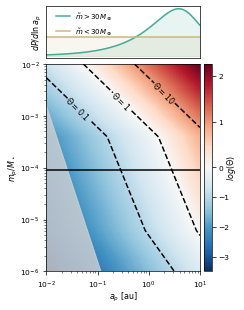

In [236]:
cm=1/2.54

# Constants (AU, solar masses)
M_star = 1.0
R_jup = 0.0004779  # AU

# Parameter grid
a_planet = np.logspace(-2, 1, 200)      # AU
mass_ratio = np.logspace(-6, -2, 200)   # m_p / M_star

A, Q = np.meshgrid(a_planet, mass_ratio)
M_planet = Q * M_star

# Safronov number
theta = safronov_number(M_star, A, M_planet)

# Heatmap
fig = plt.figure(figsize=(8.7*cm, 11*cm))

gs = fig.add_gridspec(
    2, 2,
    height_ratios=[1, 4],
    width_ratios=[20, 1],
    hspace=0.04,
    wspace=0.05,
)

ax_top = fig.add_subplot(gs[0, 0])
ax = fig.add_subplot(gs[1, 0], sharex=ax_top)
cax = fig.add_subplot(gs[1, 1])

pcm = ax.pcolormesh(
    A, Q, np.log10(theta),
    norm=TwoSlopeNorm(
        vmin=np.log10(theta.min()),
        vcenter=0,
        vmax=np.log10(theta.max())
    ),
    cmap="RdBu_r",
    shading="auto"
)

# Roche limit curve
a_roche = 2.44 * R_jup * mass_ratio**(-1/3)

# Shade everything LEFT of the Roche limit gray
ax.fill_betweenx(
    mass_ratio,          # y values
    1e-6,                # left boundary of shading (pick below your x-min)
    a_roche,             # right boundary = Roche limit
    color="lightgray",
    alpha=0.8,
    zorder=1,
    label="Inside Roche limit"
)

# Plot the Roche limit itself on top
# ax.plot(
#     a_roche,
#     mass_ratio,
#     color="black",
#     linestyle="--",
#     linewidth=2,
#     zorder=4,
#     label="Roche limit"
# )

cbar = fig.colorbar(pcm, cax=cax, pad=0.03)
cbar.set_label(r"$log(\Theta)$", labelpad=-5)
# ticks = [-1,0, 1]
# cbar.set_ticks(ticks)
# cbar.set_ticklabels([rf"$10^{{{t}}}$" for t in ticks])

# Theta = 1 boundary
contour1 = ax.contour(
    A, Q, theta,
    levels=[1],
    colors="black",
    linewidths=1.5,
    linestyles='dashed'
)

contour10 = ax.contour(
    A, Q, theta,
    levels=[10],
    colors="black",
    linewidths=1.5,
    linestyles='dashed'
)

contour_one_tenth = ax.contour(
    A, Q, theta,
    levels=[0.1],
    colors="black",
    linewidths=1.5,
    linestyles='dashed'
)

labels1 = ax.clabel(
    contour1,
    fmt={1: r'$\Theta=1$'},
    inline=True,
    inline_spacing=3,
    manual=[(1e-1, 10**-2.7)],
)

labels2 = ax.clabel(
    contour10,
    fmt={10: r'$\Theta=10$'},
    inline=True,
    inline_spacing=15,
    manual=[(10**0.4, 10**-2.5)],
)
labels3 = ax.clabel(
    contour_one_tenth,
    fmt={0.1: r'$\Theta=0.1$'},
    inline=True,
    inline_spacing=-3.5,
    manual=[(10**-1.85, 10**-2.85)],
)

labels1[0].set_rotation(-45)
labels2[0].set_rotation(-45)
labels3[0].set_rotation(-45)


# Assumes A, Q, and theta are your existing 2D arrays
R_jup = 0.0004779  # AU

# Valid orbits: outside the Roche limit
a_roche = 2.44 * R_jup * Q**(-1/3)
valid = A >= a_roche

# Occurrence rate densities per dln(a) dln(q)



# avoid forbidden region if desired
# fulton = np.where(valid, fulton, np.nan)
# cassan = np.where(valid, cassan, np.nan)


# ----------------------------
# Constants
# ----------------------------
M_earth_over_M_sun = 3.003e-6
q30 = 30 * M_earth_over_M_sun   # 30 Earth masses in solar-mass units

a_min = a_planet.min()
a_max = a_planet.max()
q_min = mass_ratio.min()
q_max = mass_ratio.max()




# If you already have a legend and want to append:

# ax.legend(handles + legend_handles, labels + [h.get_label() for h in legend_handles],
#           loc='upper right')



ax.hlines(3.00274e-6*30, 1e-2,1e2, color='black',zorder=15, label=r'$\frac{m_p}{M_*}=30 M_{\oplus}$')

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel(r"$a_p$ [au]",labelpad=0)
ax.set_ylabel(r"$m_p/M_\star$", labelpad=0)

# Fulton distribution
fulton = (
    a_planet**(-0.86)
    * (1 - np.exp(-(a_planet / 3.6)**1.58))
)

# Normalize over ln(a)
fulton /= np.trapz(fulton, x=np.log(a_planet))

# Cassan / flat-in-log-a distribution
cassan = np.ones_like(a_planet)
cassan /= np.trapz(cassan, x=np.log(a_planet))

ax_top.plot(
    a_planet,
    fulton,
    color="#44AA99",
    linewidth=1.5,
    label=r"$\tilde{m}>30 M_\oplus$"
)

ax_top.fill_between(
    a_planet,
    fulton,
    color="#44AA99",
    alpha=0.12,
)

ax_top.plot(
    a_planet,
    cassan,
    color="#CCB974",
    linewidth=1.5,
    label=r"$\tilde{m}<30 M_\oplus$"
)


ax_top.fill_between(
    a_planet,
    cassan,
    color="#CCB974",
    alpha=0.12,
)

ax_top.set_xscale("log")
ax_top.set_ylabel(r"$dP/d\ln a_p$", fontsize=8, labelpad=2)
ax_top.tick_params(axis="both", labelsize=7, pad=2)

ax_top.legend(
    loc="upper left",
    bbox_to_anchor=(0.02, 1.04),
    frameon=False,
    fontsize=7,
)


ax.set_xlim(1e-2,1e1)
ax_top.tick_params(
    axis="both",
    which="both",
    bottom=False,
    top=False,
    left=False,
    right=False,
    labelbottom=False,
    labelleft=False,
)

fig.subplots_adjust(
    left=0.19,
    right=0.86,
    bottom=0.12,
    top=0.97,
    hspace=0.06,
)

plt.savefig('/Users/haydenmonk/Downloads/HPCC/Mass_Fraction/Outputs/Visualizations/safronov_heatmap.png', dpi=500, facecolor='white',bbox_inches='tight')

In [135]:


# Assumes A, Q, and theta are your existing 2D arrays
R_jup = 0.0004779  # AU

# Valid orbits: outside the Roche limit
a_roche = 2.44 * R_jup * Q**(-1/3)
valid = A >= a_roche

# Occurrence rate densities per dln(a) dln(q)

# Fulton et al. (2021), broken power law in a
fulton = A**(-0.86) * (
    1 - np.exp(-(A / 3.6)**1.59)
)

# Cassan et al. (2012), power law in planet mass
# At fixed stellar mass, m_p^-0.73 is proportional to q^-0.73
cassan = Q**(-0.73)

# Integrate on the logarithmic grid
dln_a = np.gradient(np.log(a_planet))
dln_q = np.gradient(np.log(mass_ratio))
d_area = dln_q[:, None] * dln_a[None, :]

def above_safronov_threshold(distribution, domain=None):
    mask = valid.copy()
    if domain is not None:
        mask &= domain

    weights = distribution * d_area
    total = np.sum(weights[mask])
    above = np.sum(weights[mask & (theta > 1)])

    return above / total

print(f"Fulton: {above_safronov_threshold(fulton):.2%}")
print(f"Cassan: {above_safronov_threshold(cassan):.2%}")


Fulton: 45.50%
Cassan: 4.07%


In [136]:
# Fulton occurrence density on your existing grid
fulton = A**(-0.86) * (1 - np.exp(-(A / 3.6)**1.59))

# Area elements in logarithmic coordinates
dln_a = np.gradient(np.log(a_planet))
dln_q = np.gradient(np.log(mass_ratio))
weights = fulton * dln_q[:, None] * dln_a[None, :]

# Restrict to Fulton mass range and outside Roche limit
q30 = 30 * 3.003e-6
domain = (Q >= q30) & valid

total = weights[domain].sum()

print("Overall:", weights[domain & (theta > 1)].sum() / total)

for i in range(5):
    band = (
        (A >= a_edges_fulton[i]) &
        (A < a_edges_fulton[i+1]) &
        domain
    )

    band_total = weights[band].sum()
    band_above = weights[band & (theta > 1)].sum()

    print(
        f"Band {i+1}: "
        f"{band_total / total:.1%} of planets, "
        f"{band_above / band_total:.1%} above Theta=1"
    )

Overall: 0.7525868765171252
Band 1: 19.5% of planets, 28.0% above Theta=1
Band 2: 20.2% of planets, 60.3% above Theta=1
Band 3: 19.7% of planets, 86.2% above Theta=1
Band 4: 20.0% of planets, 100.0% above Theta=1
Band 5: 19.8% of planets, 100.0% above Theta=1


In [140]:
# Bounds in AU and solar masses
M_earth = 3.003e-6
M_jup = 9.545e-4

# Approximate study domains
fulton_bounds = {
    "a": (0.03, 30),
    "q": (30*M_earth, 6000*M_earth)
}

cassan_bounds = {
    "a": (0.5, 10),
    "q": (M_earth, 30*M_earth)
}

def area_fraction(bounds):
    a_min, a_max = bounds["a"]
    q_min, q_max = bounds["q"]

    # Generate grid covering the study's full domain
    a = np.logspace(np.log10(a_min), np.log10(a_max), 1000)
    q = np.logspace(np.log10(q_min), np.log10(q_max), 1000)

    A_grid, Q_grid = np.meshgrid(a, q)

    # Constant Jupiter radius
    theta_grid = safronov_number(
        1.0, A_grid, Q_grid
    )

    # Exclude Roche-forbidden region
    valid = A_grid >= 2.44 * R_jup * Q_grid**(-1/3)

    return np.sum(valid & (theta_grid > 1)) / np.sum(valid)

print(f"Fulton: {area_fraction(fulton_bounds):.2%}")
print(f"Cassan: {area_fraction(cassan_bounds):.2%}")

Fulton: 62.52%
Cassan: 18.87%


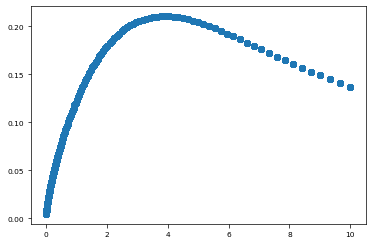

In [138]:
plt.scatter(A, fulton)

In [139]:
theta_grid = safronov_number(1.0, A_grid, Q_grid, R_jup)

theta_expected = A_grid * Q_grid / R_jup

print("Function range:", theta_grid.min(), theta_grid.max())
print("Expected range:", theta_expected.min(), theta_expected.max())
print("Maximum difference:", np.max(np.abs(theta_grid - theta_expected)))

NameError: name 'A_grid' is not defined